# Which facets help identify better comparable companies?
### Two clearly separated X-learner analyses

We investigate the same 293 reviewed company pairs in two ways:

- **[Method A: original 0/1/2 rating](#method-a)** — how does a stronger facet match relate to the expected human rating? Units: **rating points**.
- **[Method B: combined peer/non-peer](#method-b)** — how does a stronger facet match relate to the chance of any acceptable peer label? Units: **percentage points**.
- **[Compare findings and next steps](#comparison)** — which hypotheses persist, and which depend on the outcome definition?

Each method has its own explanation, results, sensitivity analysis and diagnostics. Shared study design appears first. The estimates are exploratory adjusted associations within a selected, single-reviewer cohort, not identified causal effects or improvements in either matching pipeline.

The original `facet_uplift.ipynb` remains the earlier binary technical/raw notebook. The previous stakeholder edition is archived; its binary experiment results are preserved.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_manifest.json").exists())
BINARY_RUN = ROOT / "outputs-local/v1/facet_uplift/20261113T190330202875Z"
RATING_RUN = ROOT / "outputs-local/v1/facet_uplift/20261113T201612982633Z"
RUN = BINARY_RUN
manifest = json.loads((RUN / "manifest.json").read_text())
features = pd.read_csv(RUN / "pair_features.csv")
summary = pd.read_csv(RUN / "facet_summary.csv")
effects = pd.read_csv(RUN / "oof_effects.csv")
folds = pd.read_csv(RUN / "fold_diagnostics.csv")
bins = pd.read_csv(RUN / "uplift_bins.csv")
primary = summary[summary.rule.eq("primary")].copy()
assert len(features) == manifest["pairs"] and features.target.nunique() == manifest["targets"]
assert not features.duplicated(["target", "comp"]).any()
assert len(summary) == 44
PRESENTATION = RATING_RUN / "presentation" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
PRESENTATION.mkdir(parents=True, exist_ok=False)
NAMES = {"primary_services":"Services", "primary_products":"Products", "customer_segment":"Customers",
         "end_markets":"End markets", "offering_description":"Core offering", "business_model":"Business model",
         "revenue_model":"Revenue model", "value_chain_position":"Value-chain position",
         "geography_served":"Geography", "regulatory_exposure":"Regulation",
         "specialization":"Specialization", "distribution_channels":"Sales channels"}
BLUE, TEAL, ORANGE, GRAY = "#315b85", "#217f79", "#ba762c", "#a9b1bb"
plt.rcParams.update({"figure.dpi":110, "font.size":11, "axes.spines.top":False,
                     "axes.spines.right":False, "axes.titleweight":"bold"})
def save(fig, name, note):
    fig.text(.02, .012, note, fontsize=9, color="#424b55", va="bottom")
    fig.tight_layout(rect=(0,.065,1,.94))
    fig.savefig(PRESENTATION / (name + ".png"), dpi=170, bbox_inches="tight", facecolor="white")
    plt.show()
def row(source, facet, rule="primary"):
    return summary.loc[summary.source.eq(source)&summary.facet.eq(facet)&summary.rule.eq(rule)].iloc[0]
def pp(value): return f"{100*value:+.1f} pp"
def block(title, text): display(Markdown(f"**{title}**  \n{text}"))
print(f"Pinned experiment: {RUN.name}; source commit: {manifest['commit'][:8]}")
print("Figures are exported to:", PRESENTATION.relative_to(ROOT))
DATA = {}
for mode, folder in [("rating", RATING_RUN), ("peer", BINARY_RUN)]:
    DATA[mode] = {name: pd.read_csv(folder / f"{name}.csv") for name in ["facet_summary", "oof_effects", "fold_diagnostics", "pair_features"]}
    DATA[mode]["manifest"] = json.loads((folder / "manifest.json").read_text())
pd.testing.assert_frame_equal(DATA['rating']['pair_features'], DATA['peer']['pair_features'])
keys=['source','facet','rule','fold']
support_cols=['train_n','test_n','controls','treated','targets_arm_0','targets_arm_1','status']
pd.testing.assert_frame_equal(DATA['rating']['fold_diagnostics'].sort_values(keys)[keys+support_cols].reset_index(drop=True), DATA['peer']['fold_diagnostics'].sort_values(keys)[keys+support_cols].reset_index(drop=True))
print('Same pair features, target folds, treatment thresholds and arm support in both methods.')
def effect_text(value, mode):
    return f"{value:+.3f} rating points" if mode=='rating' else f"{100*value:+.1f} percentage points"
def result_row(mode,source,facet,rule='primary'):
    s=DATA[mode]['facet_summary']
    return s.loc[s.source.eq(source)&s.facet.eq(facet)&s.rule.eq(rule)].iloc[0]


Pinned experiment: 20261113T190330202875Z; source commit: 44727659
Figures are exported to: outputs-local/v1/facet_uplift/20261113T201612982633Z/presentation/20261113T202212020669Z
Same pair features, target folds, treatment thresholds and arm support in both methods.


## Shared design: two facet signals, one human reference

**B3 features** are per-facet 50/50 blends of embedding and word-overlap similarity from Sonnet company profiles. **Agent features** are cited 0/25/50/75/100 facet-match ratings. They are fitted separately using the other facets from that source as context.

Overall agent grade, S, E, total B3, candidate rank and reviewer notes are excluded from predictors. The sources have different definitions of a strong match and different usable populations; their effect magnitudes are not a direct comparison of source quality.

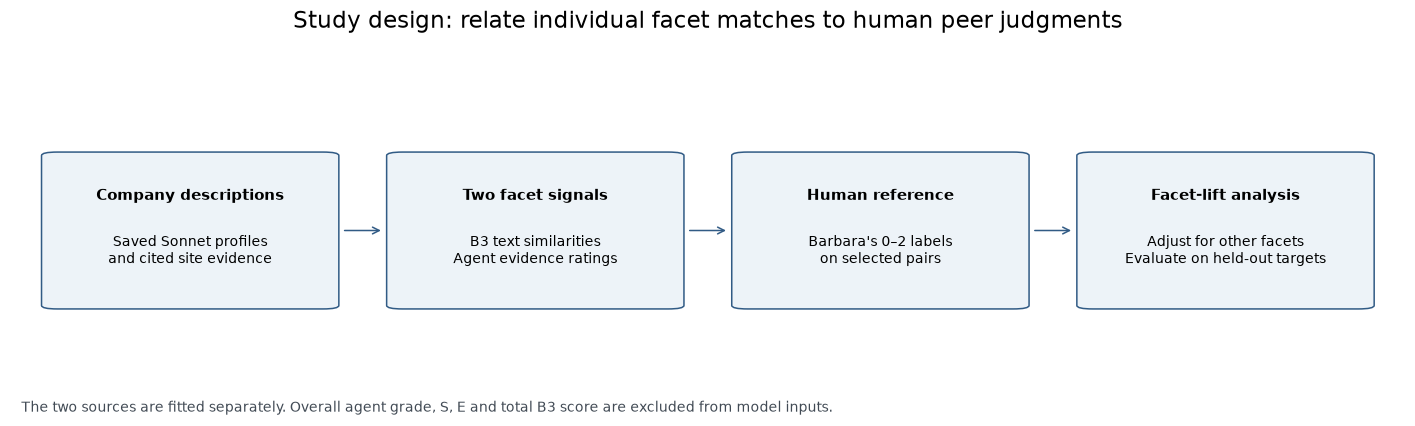

In [2]:
fig, ax = plt.subplots(figsize=(13,3.8)); ax.set(xlim=(-.025,1.025),ylim=(0,1)); ax.axis("off")
boxes=[(.01,"Company descriptions", "Saved Sonnet profiles\nand cited site evidence"),
       (.27,"Two facet signals", "B3 text similarities\nAgent evidence ratings"),
       (.53,"Human reference", "Barbara's 0–2 labels\non selected pairs"),
       (.79,"Facet-lift analysis", "Adjust for other facets\nEvaluate on held-out targets")]
for x,title,body in boxes:
    ax.add_patch(FancyBboxPatch((x,.24),.20,.52,boxstyle="round,pad=.012",facecolor="#edf3f8",edgecolor=BLUE))
    ax.text(x+.10,.62,title,ha="center",va="center",weight="bold",fontsize=10)
    ax.text(x+.10,.43,body,ha="center",va="center",fontsize=9)
for a,b in zip(boxes[:-1],boxes[1:]):
    ax.annotate("",xy=(b[0]-.014,.5),xytext=(a[0]+.214,.5),arrowprops={"arrowstyle":"->","color":BLUE})
fig.suptitle("Study design: relate individual facet matches to human peer judgments",fontsize=15)
save(fig,"01_approach","The two sources are fitted separately. Overall agent grade, S, E and total B3 score are excluded from model inputs.")

## The original human labels remain available

The full dataset contains **0 = non-peer, 1 = adjacent peer, 2 = direct peer**. Method A keeps these numerical values. Method B combines grades 1 and 2 only within its own outcome definition.

There is one reviewer (Barbara), and only 24 direct-peer labels. The pair list was selected from existing candidates and has already been used in pipeline development. It is not an untouched independent benchmark.

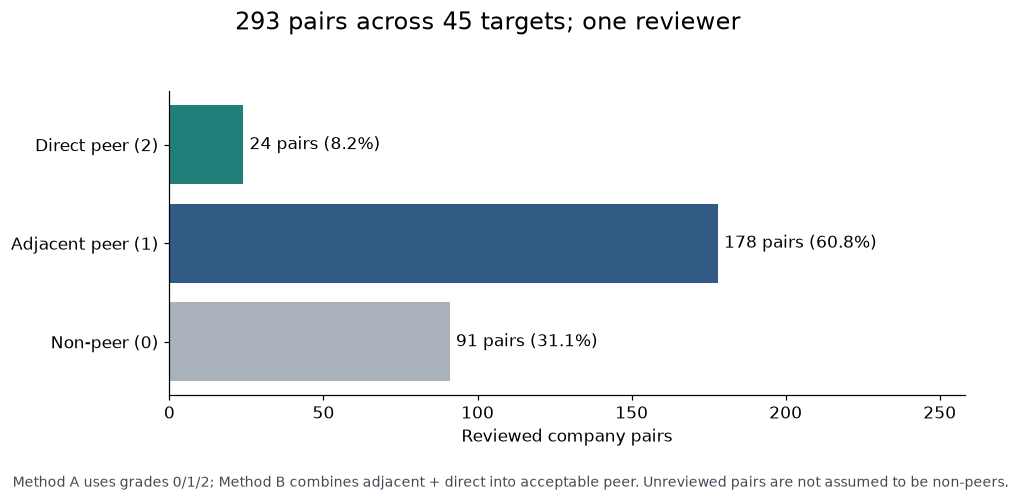

**Reading the cohort**  
202 of 293 pairs (68.9%) are acceptable peers. Only 24 are direct peers; Method A retains the grade distinctions, while Method B measures the combined peer outcome.

In [3]:
counts=features.score_barbara.value_counts().reindex([0,1,2],fill_value=0)
fig,ax=plt.subplots(figsize=(9,4.5))
bars=ax.barh(["Non-peer (0)","Adjacent peer (1)","Direct peer (2)"],counts,color=[GRAY,BLUE,TEAL])
for bar,n in zip(bars,counts): ax.text(n+2,bar.get_y()+bar.get_height()/2,f"{n} pairs ({n/len(features):.1%})",va="center")
ax.set(xlim=(0,max(counts)*1.45),xlabel="Reviewed company pairs")
fig.suptitle(f"{len(features)} pairs across {features.target.nunique()} targets; one reviewer",fontsize=16)
save(fig,"02_review_cohort","Method A uses grades 0/1/2; Method B combines adjacent + direct into acceptable peer. Unreviewed pairs are not assumed to be non-peers.")
block("Reading the cohort",f"{int(counts[1]+counts[2])} of {len(features)} pairs ({(counts[1]+counts[2])/len(features):.1%}) are acceptable peers. Only {int(counts[2])} are direct peers; Method A retains the grade distinctions, while Method B measures the combined peer outcome.")

## Shared comparison and target validation

The **treatment stays binary in both methods**: stronger vs weaker match on one facet. Only the outcome and its response model change.

- Primary B3 contrast: above vs at/below the training median. Stricter: upper vs lower third, omitting the middle.
- Primary agent contrast: 75/100 vs 0/25/50. Stricter: 75/100 vs 0/25, omitting 50. Unknown is always missing.

Both analyses use five outer groups of target companies and three inner target groups for pseudo-effects. Each outer target is held out once; each training target has equal total weight. Median imputation, missingness indicators and scaling are fitted within training. At least 15 rows across five targets per arm are required. Summaries retain estimated propensities 0.1–0.9, then weight retained targets equally.

A comp company can occur in more than one target group. The experiment assesses held-out targets in the shared company universe, not entirely unseen entities.

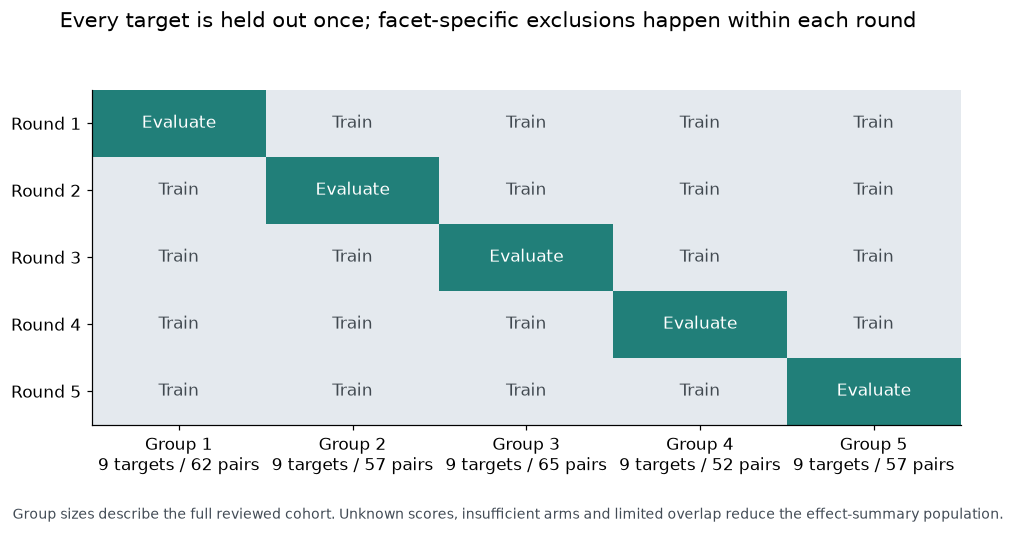

In [4]:
import sys
sys.path.insert(0,str(ROOT / "v1/scripts"))
from facet_uplift import group_splits
splits=list(group_splits(features.target.to_numpy()))
fig,ax=plt.subplots(figsize=(9,4.8))
ax.imshow(np.eye(5),cmap=ListedColormap(["#e4e9ee",TEAL]),vmin=0,vmax=1,aspect="auto")
for i,(train,test) in enumerate(splits):
    for j in range(5):
        ax.text(j,i,"Evaluate" if i==j else "Train",ha="center",va="center",color="white" if i==j else "#414950")
ax.set_xticks(range(5),[f"Group {i+1}\n{features.iloc[te].target.nunique()} targets / {len(te)} pairs" for i,(_,te) in enumerate(splits)])
ax.set_yticks(range(5),[f"Round {i+1}" for i in range(5)])
fig.suptitle("Every target is held out once; facet-specific exclusions happen within each round",fontsize=14)
save(fig,"03_target_validation","Group sizes describe the full reviewed cohort. Unknown scores, insufficient arms and limited overlap reduce the effect-summary population.")

## How the X-learner operates in both analyses

1. Fit separate expected-outcome models on strong and weak training pairs.
2. Impute the alternative outcome using models trained on other target groups: D1 = observed outcome − predicted weak-match outcome; D0 = predicted strong-match outcome − observed outcome.
3. Fit two ridge regressions to these imputed effects.
4. Combine their predictions with an estimated strong-match propensity: e(X) × effect model 0 + (1 − e(X)) × effect model 1.

The propensity model is logistic in both methods; ridge effect regressions use alpha=10. There are no observed true effect labels. We can evaluate response prediction on held-out human labels, but that does not directly validate the accuracy of estimated lift.

All uncertainty plots bootstrap targets with fitted predictions held fixed. They omit refitting, reviewer, threshold and candidate-selection uncertainty; they are not full causal confidence intervals or multiple-testing-adjusted significance tests.

In [5]:
def plot_effects(mode):
    s=DATA[mode]['facet_summary']; s=s[s.rule.eq('primary')]
    factor=1 if mode=='rating' else 100
    unit='rating points' if mode=='rating' else 'percentage points'
    values=s[['uplift_ci_low','uplift_ci_high']].to_numpy(float)*factor
    lo=min(0.,np.nanmin(values)); hi=max(0.,np.nanmax(values)); width=max(hi-lo,.1)
    left=lo-.12*width; right=hi+.10*width; count_x=right+.05*width
    fig,axes=plt.subplots(1,2,figsize=(15,7.3),sharex=True)
    for ax,source in zip(axes,['b3','agent']):
        part=s[s.source.eq(source)].sort_values('mean_uplift',ascending=False,na_position='last').reset_index(drop=True)
        for i,r in part.iterrows():
            if pd.notna(r.mean_uplift):
                color=BLUE if r.status=='complete' else ORANGE
                ax.plot([factor*r.uplift_ci_low,factor*r.uplift_ci_high],[i,i],color=color,lw=2)
                ax.scatter(factor*r.mean_uplift,i,color=color,zorder=3)
                ax.text(count_x,i,f'{int(r.overlap_pairs)} pairs / {int(r.overlap_targets)} targets',va='center',fontsize=8)
            else: ax.text(.01*width,i,'Insufficient support',va='center',fontsize=9,color='#606870')
        ax.set_yticks(range(len(part)),[NAMES[f] for f in part.facet]);ax.set_ylim(len(part)-.5,-.5)
        ax.set_xlim(left,right+.85*width);ax.axvline(0,color=GRAY,lw=.8)
        step=.2 if mode=='rating' else 10
        ax.set_xticks(np.arange(np.ceil(left/step)*step,right+1e-9,step))
        ax.set(title=source.upper(),xlabel=f'Estimated adjusted lift ({unit})')
    label='A: original 0/1/2 rating' if mode=='rating' else 'B: combined peer/non-peer'
    fig.suptitle(f'Method {label} — primary estimates',fontsize=15)
    save(fig,f'{mode}_primary_effects','Ranges hold predictions fixed; orange = incomplete evaluation rounds. Source contrasts/populations differ. No causal identification.')

def plot_sensitivity(mode):
    s=DATA[mode]['facet_summary']; factor=1 if mode=='rating' else 100
    unit='rating points' if mode=='rating' else 'percentage points'
    vals=s.mean_uplift.dropna().to_numpy()*factor
    lo=min(0.,vals.min());hi=max(0.,vals.max());width=max(hi-lo,.1)
    fig,axes=plt.subplots(1,2,figsize=(15,7),sharex=True)
    for ax,source in zip(axes,['b3','agent']):
        names=sorted(s.loc[s.source.eq(source),'facet'].unique())
        for i,f in enumerate(names):
            a,b=result_row(mode,source,f),result_row(mode,source,f,'extreme')
            if pd.isna(a.mean_uplift) or pd.isna(b.mean_uplift):
                ax.text(.01*width,i,'Insufficient support',va='center',fontsize=9,color='#606870');continue
            ax.plot([factor*a.mean_uplift,factor*b.mean_uplift],[i,i],color=GRAY)
            ax.scatter(factor*a.mean_uplift,i,color=BLUE,s=30);ax.scatter(factor*b.mean_uplift,i,color=TEAL,s=30)
            ax.text(hi+.14*width,i,f'{int(a.overlap_pairs)} → {int(b.overlap_pairs)} pairs',va='center',fontsize=8)
        ax.set_yticks(range(len(names)),[NAMES[f] for f in names]);ax.set_ylim(len(names)-.5,-.5)
        ax.set_xlim(lo-.12*width,hi+.85*width);ax.axvline(0,color=GRAY,lw=.8)
        step=.1 if mode=='rating' else 10
        ax.set_xticks(np.arange(np.ceil((lo-.12*width)/step)*step,hi+.07*width+1e-9,step))
        ax.set(title=source.upper(),xlabel=f'Estimated adjusted lift ({unit})')
    from matplotlib.lines import Line2D
    fig.legend(handles=[Line2D([],[],marker='o',linestyle='',color=BLUE,label='Primary'),Line2D([],[],marker='o',linestyle='',color=TEAL,label='Stricter')],loc='upper center',bbox_to_anchor=(.5,.94),ncol=2,frameon=False)
    fig.suptitle(f"{'Rating' if mode=='rating' else 'Combined binary'} outcome: sensitivity to match definition",fontsize=15)
    save(fig,f'{mode}_sensitivity','Stricter contrasts change both the match definition and included pairs. Counts are primary → stricter retained cases; not new observations.')

def show_findings(mode):
    s=DATA[mode]['facet_summary'];p=s[s.rule.eq('primary')]
    for source in ['b3','agent']:
        complete=p[p.source.eq(source)&p.status.eq('complete')].sort_values('mean_uplift',ascending=False)
        text='; '.join(f'{NAMES[r.facet]} {effect_text(r.mean_uplift,mode)}' for _,r in complete.head(4).iterrows())
        block(f'{source.upper()}: largest complete primary estimates',text+'. Descriptive ordering, not a proven ranking of facet importance.')
    display(p[['source','facet','status','folds_ok','overlap_pairs','overlap_targets','mean_uplift','uplift_ci_low','uplift_ci_high']].rename(columns={'mean_uplift':'Estimated lift','uplift_ci_low':'Fixed-prediction lower','uplift_ci_high':'Fixed-prediction upper'}).round(3))


<a id="method-a"></a>
## Method A — original 0/1/2 human rating

**Question:** is a stronger facet match associated with a higher expected human rating, using the distinction between non-peer, adjacent and direct?

**Outcome:** the original numerical score: 0, 1, or 2. We fit separate ridge response models (alpha=10) to each treatment arm and bound their expected-rating predictions to [0,2]. Effect models remain ridge regressions; the binary propensity model and all folds, feature inputs, treatment definitions and support rules are unchanged.

**Units:** a lift of **+0.25 rating points** is a difference in expected rating. It does not mean +25 percentage points or that every pair gains a quarter of a category.

**Assumption:** 0→1 and 1→2 are equally spaced. This is a numerical-score analysis, not a multiclass model estimating separate probabilities of 0, 1 and 2. It includes direct-peer information, but does not specifically isolate the probability of a direct peer.

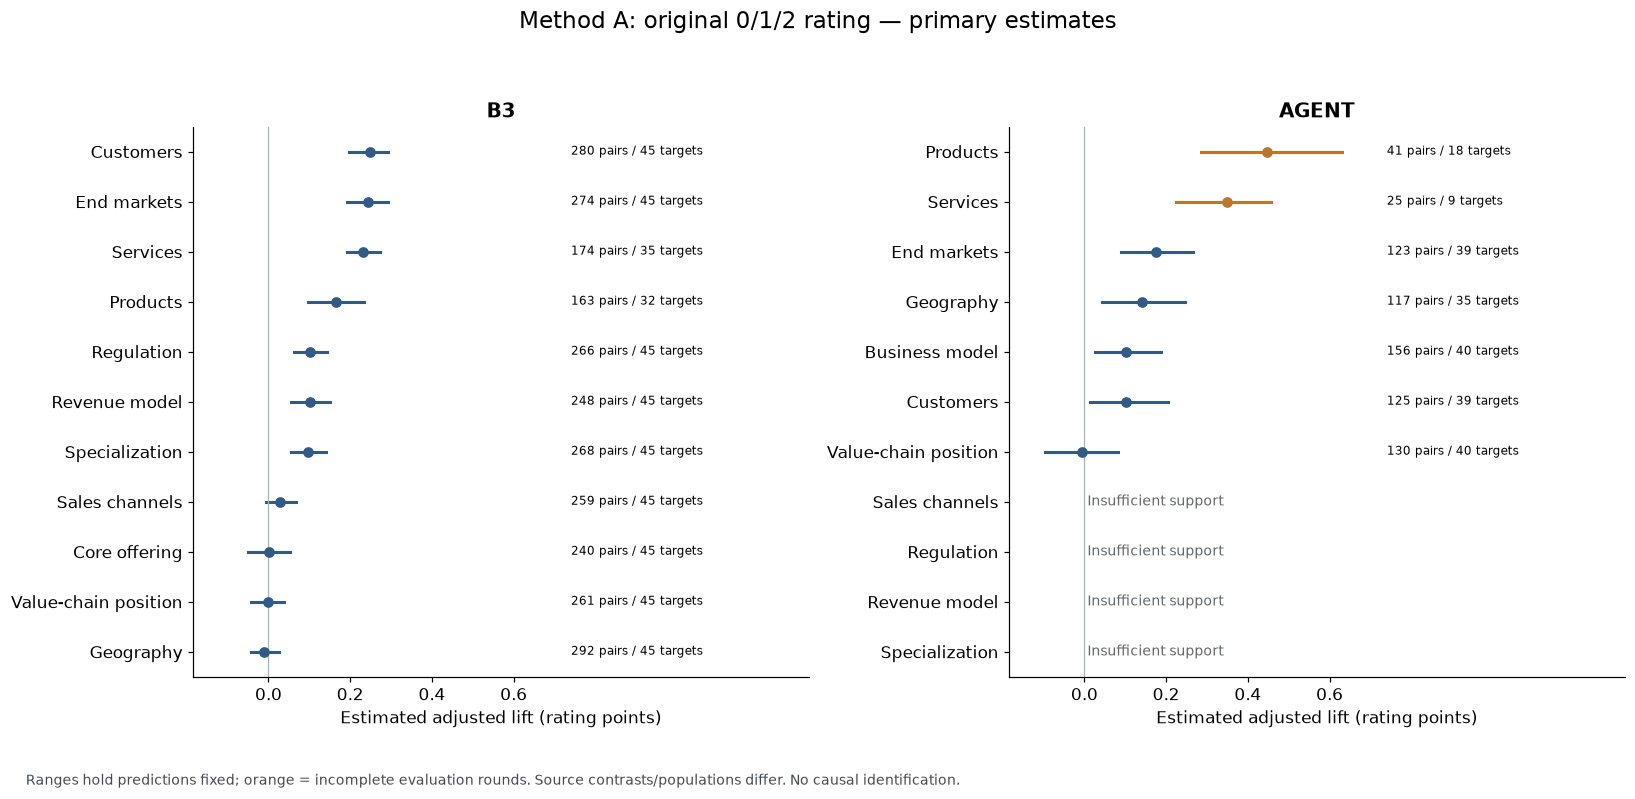

**B3: largest complete primary estimates**  
Customers +0.247 rating points; End markets +0.242 rating points; Services +0.230 rating points; Products +0.165 rating points. Descriptive ordering, not a proven ranking of facet importance.

**AGENT: largest complete primary estimates**  
End markets +0.175 rating points; Geography +0.140 rating points; Business model +0.102 rating points; Customers +0.101 rating points. Descriptive ordering, not a proven ranking of facet importance.

,source,facet,status,folds_ok,overlap_pairs,overlap_targets,Estimated lift,Fixed-prediction lower,Fixed-prediction upper
1,agent,business_model,complete,5,156.0,40.0,0.102,0.026,0.187
3,agent,customer_segment,complete,5,125.0,39.0,0.101,0.014,0.205
5,agent,distribution_channels,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN
7,agent,end_markets,complete,5,123.0,39.0,0.175,0.091,0.266
9,agent,geography_served,complete,5,117.0,35.0,0.140,0.044,0.246
11,agent,primary_products,partial_or_unsupported,4,41.0,18.0,0.446,0.286,0.631
13,agent,primary_services,partial_or_unsupported,3,25.0,9.0,0.349,0.223,0.457
15,agent,regulatory_exposure,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN
17,agent,revenue_model,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN
19,agent,specialization,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN


In [6]:
plot_effects('rating')
show_findings('rating')

### Method A — sensitivity and interpretation

We repeat the rating analysis with the stricter match definition. A positive direction under both comparisons is a useful hypothesis, not proof of a facet's causal importance. Partial agent results should be read with their small retained samples and incomplete rounds.

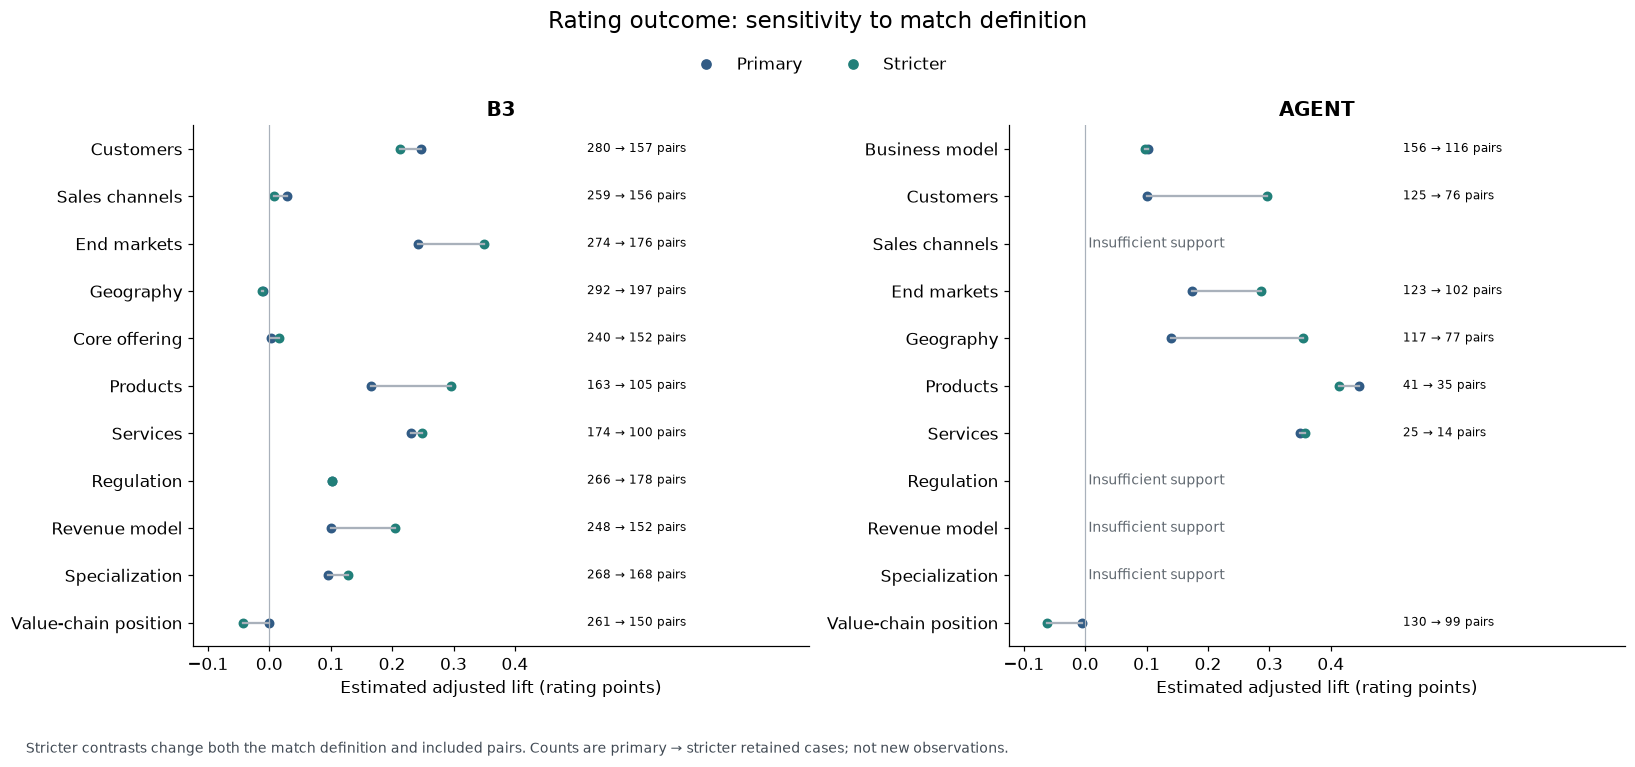

mean_uplift         overlap_pairs          \
rule                             extreme primary       extreme primary   
source facet                                                             
agent  business_model              0.098   0.102         116.0   156.0   
       customer_segment            0.296   0.101          76.0   125.0   
       distribution_channels         NaN     NaN           NaN     NaN   
       end_markets                 0.287   0.175         102.0   123.0   
       geography_served            0.354   0.140          77.0   117.0   
       primary_products            0.412   0.446          35.0    41.0   
       primary_services            0.358   0.349          14.0    25.0   
       regulatory_exposure           NaN     NaN           NaN     NaN   
       revenue_model                 NaN     NaN           NaN     NaN   
       specialization                NaN     NaN           NaN     NaN   
       value_chain_position       -0.063  -0.005          99.0   130.0   
b3     customer_segment            0.213   0.247         157.0   280.0   
       distribution_channels       0.007   0.029         156.0   259.0   
       end_markets                 0.350   0.242         176.0   274.0   
       geography_served           -0.013  -0.010         197.0   292.0   
       offering_description        0.016   0.002         152.0   240.0   
       primary_products            0.296   0.165         105.0   163.0   
       primary_services            0.248   0.230         100.0   174.0   
       regulatory_exposure         0.101   0.102         178.0   266.0   
       revenue_model               0.205   0.101         152.0   248.0   
       specialization              0.129   0.096         168.0   268.0   
       value_chain_position       -0.043  -0.001         150.0   261.0   

                             folds_ok          
rule                          extreme primary  
source facet                                   
agent  business_model             5.0     5.0  
       customer_segment           5.0     5.0  
       distribution_channels      0.0     0.0  
       end_markets                5.0     5.0  
       geography_served           5.0     5.0  
       primary_products           4.0     4.0  
       primary_services           3.0     3.0  
       regulatory_exposure        0.0     0.0  
       revenue_model              0.0     0.0  
       specialization             0.0     0.0  
       value_chain_position       5.0     5.0  
b3     customer_segment           5.0     5.0  
       distribution_channels      5.0     5.0  
       end_markets                5.0     5.0  
       geography_served           5.0     5.0  
       offering_description       5.0     5.0  
       primary_products           5.0     5.0  
       primary_services           5.0     5.0  
       regulatory_exposure        5.0     5.0  
       revenue_model              5.0     5.0  
       specialization             5.0     5.0  
       value_chain_position       5.0     5.0

In [7]:
plot_sensitivity('rating')
s=DATA['rating']['facet_summary']
display(s.pivot(index=['source','facet'],columns='rule',values=['mean_uplift','overlap_pairs','folds_ok']).round(3))

### Method A — how well are held-out ratings predicted?

**MAE** is the average absolute error in rating points; lower is better. **RMSE** gives larger mistakes more weight. The baseline always predicts the target-weighted average rating from the training fold.

These are outcome-prediction diagnostics, not measurements of true facet-effect accuracy. They use pair-weighted errors, whereas the lift summary weights retained targets equally. DR is a separate adjusted diagnostic, not effect ground truth.

In [8]:
s=DATA['rating']['facet_summary'];p=s[s.rule.eq('primary')]
display(p[['source','facet','mae','baseline_mae','rmse','baseline_rmse','dr_adjusted_difference','outside_rating_effect_range']].round(3))
r=result_row('rating','agent','customer_segment')
block('Rating-method sensitivity concern',f"Agent customers: X-learner {effect_text(r.mean_uplift,'rating')}; DR diagnostic {effect_text(r.dr_adjusted_difference,'rating')}. The opposite signs warrant case review.")


,source,facet,mae,baseline_mae,rmse,baseline_rmse,dr_adjusted_difference,outside_rating_effect_range
1,agent,business_model,0.365,0.479,0.463,0.582,0.036,0.0
3,agent,customer_segment,0.369,0.511,0.447,0.605,-0.106,0.0
5,agent,distribution_channels,NaN,NaN,NaN,NaN,NaN,NaN
7,agent,end_markets,0.382,0.484,0.459,0.581,0.121,0.0
9,agent,geography_served,0.363,0.474,0.445,0.606,0.180,0.0
11,agent,primary_products,0.387,0.448,0.477,0.555,0.320,1.0
13,agent,primary_services,0.368,0.445,0.460,0.549,0.271,0.0
15,agent,regulatory_exposure,NaN,NaN,NaN,NaN,NaN,NaN
17,agent,revenue_model,NaN,NaN,NaN,NaN,NaN,NaN
19,agent,specialization,NaN,NaN,NaN,NaN,NaN,NaN


**Rating-method sensitivity concern**  
Agent customers: X-learner +0.101 rating points; DR diagnostic -0.106 rating points. The opposite signs warrant case review.

<a id="method-b"></a>
## Method B — combined peer/non-peer (earlier analysis)

**Question:** is a stronger facet match associated with a greater chance that the reviewer accepts the pair as at least an adjacent peer?

**Outcome:** grade 0 becomes 0 (non-peer); grades 1 and 2 both become 1 (acceptable peer). This method deliberately treats adjacent and direct labels alike.

The response models are regularized logistic regressions (C=0.1), predicting peer probabilities. Ridge effect models, logistic propensity, treatment definitions, target folds and support rules follow the shared setup.

**Units:** estimates are shown in percentage points. +20 points means an estimated probability difference of 0.20; it is not +0.20 original-rating points or 20% more comps returned.

This remains the original saved binary experiment. Its numerical results are preserved, not refitted for this presentation.

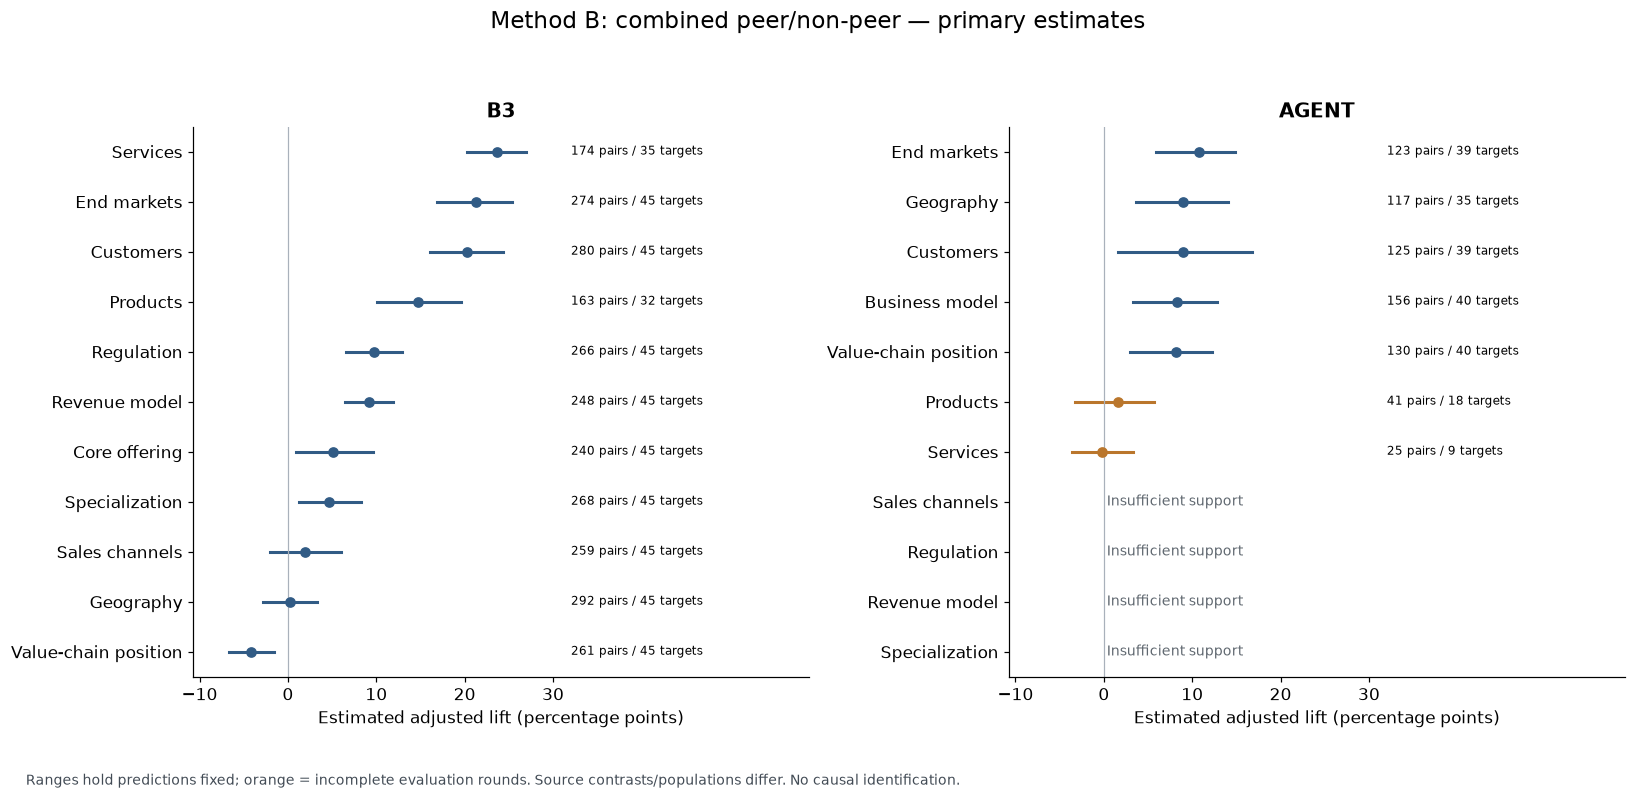

**B3: largest complete primary estimates**  
Services +23.7 percentage points; End markets +21.3 percentage points; Customers +20.2 percentage points; Products +14.7 percentage points. Descriptive ordering, not a proven ranking of facet importance.

**AGENT: largest complete primary estimates**  
End markets +10.7 percentage points; Geography +9.0 percentage points; Customers +8.9 percentage points; Business model +8.3 percentage points. Descriptive ordering, not a proven ranking of facet importance.

,source,facet,status,folds_ok,overlap_pairs,overlap_targets,Estimated lift,Fixed-prediction lower,Fixed-prediction upper
1,agent,business_model,complete,5,156.0,40.0,0.083,0.033,0.128
3,agent,customer_segment,complete,5,125.0,39.0,0.089,0.016,0.168
5,agent,distribution_channels,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN
7,agent,end_markets,complete,5,123.0,39.0,0.107,0.059,0.149
9,agent,geography_served,complete,5,117.0,35.0,0.090,0.036,0.140
11,agent,primary_products,partial_or_unsupported,4,41.0,18.0,0.016,-0.033,0.057
13,agent,primary_services,partial_or_unsupported,3,25.0,9.0,-0.002,-0.036,0.033
15,agent,regulatory_exposure,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN
17,agent,revenue_model,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN
19,agent,specialization,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN


In [9]:
plot_effects('peer')
show_findings('peer')

### Method B — sensitivity and interpretation

The stricter binary analysis changes the match contrast and the included population. Its estimates still describe the probability of any acceptable peer rating, with no distinction between adjacent and direct peers.

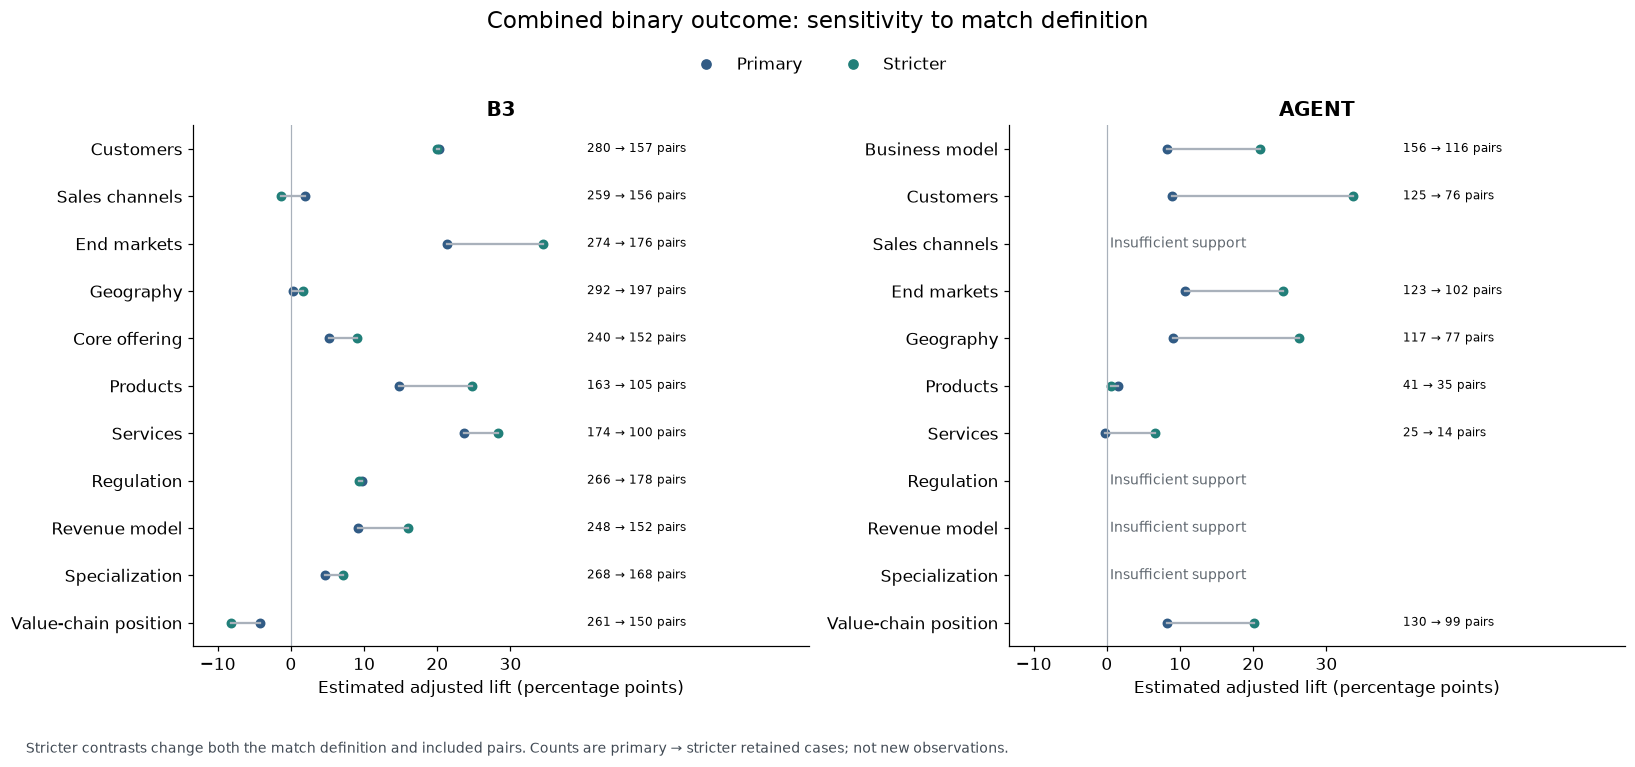

mean_uplift         overlap_pairs          \
rule                             extreme primary       extreme primary   
source facet                                                             
agent  business_model              0.209   0.083         116.0   156.0   
       customer_segment            0.336   0.089          76.0   125.0   
       distribution_channels         NaN     NaN           NaN     NaN   
       end_markets                 0.241   0.107         102.0   123.0   
       geography_served            0.263   0.090          77.0   117.0   
       primary_products            0.006   0.016          35.0    41.0   
       primary_services            0.066  -0.002          14.0    25.0   
       regulatory_exposure           NaN     NaN           NaN     NaN   
       revenue_model                 NaN     NaN           NaN     NaN   
       specialization                NaN     NaN           NaN     NaN   
       value_chain_position        0.201   0.082          99.0   130.0   
b3     customer_segment            0.199   0.202         157.0   280.0   
       distribution_channels      -0.013   0.019         156.0   259.0   
       end_markets                 0.345   0.213         176.0   274.0   
       geography_served            0.016   0.002         197.0   292.0   
       offering_description        0.090   0.051         152.0   240.0   
       primary_products            0.247   0.147         105.0   163.0   
       primary_services            0.283   0.237         100.0   174.0   
       regulatory_exposure         0.093   0.098         178.0   266.0   
       revenue_model               0.160   0.092         152.0   248.0   
       specialization              0.071   0.046         168.0   268.0   
       value_chain_position       -0.082  -0.042         150.0   261.0   

                             folds_ok          
rule                          extreme primary  
source facet                                   
agent  business_model             5.0     5.0  
       customer_segment           5.0     5.0  
       distribution_channels      0.0     0.0  
       end_markets                5.0     5.0  
       geography_served           5.0     5.0  
       primary_products           4.0     4.0  
       primary_services           3.0     3.0  
       regulatory_exposure        0.0     0.0  
       revenue_model              0.0     0.0  
       specialization             0.0     0.0  
       value_chain_position       5.0     5.0  
b3     customer_segment           5.0     5.0  
       distribution_channels      5.0     5.0  
       end_markets                5.0     5.0  
       geography_served           5.0     5.0  
       offering_description       5.0     5.0  
       primary_products           5.0     5.0  
       primary_services           5.0     5.0  
       regulatory_exposure        5.0     5.0  
       revenue_model              5.0     5.0  
       specialization             5.0     5.0  
       value_chain_position       5.0     5.0

In [10]:
plot_sensitivity('peer')
s=DATA['peer']['facet_summary']
display(s.pivot(index=['source','facet'],columns='rule',values=['mean_uplift','overlap_pairs','folds_ok']).round(3))

### Method B — how well are held-out peer probabilities predicted?

Brier loss measures probability error; lower is better. AUC assesses discrimination between acceptable peers and non-peers. The baseline is the target-weighted average binary outcome from training.

Neither metric establishes the accuracy of estimated facet lift. Brier/AUC cannot be directly compared to Method A's MAE/RMSE, which assess a different outcome on a different scale.

In [11]:
s=DATA['peer']['facet_summary'];p=s[s.rule.eq('primary')]
display(p[['source','facet','brier','baseline_brier','response_auc','dr_adjusted_difference','outside_probability_range']].round(3))
r=result_row('peer','agent','customer_segment')
block('Binary-method sensitivity concern',f"Agent customers: X-learner {effect_text(r.mean_uplift,'peer')}; DR diagnostic {effect_text(r.dr_adjusted_difference,'peer')}. The methods disagree on the sign here as well.")

,source,facet,brier,baseline_brier,response_auc,dr_adjusted_difference,outside_probability_range
1,agent,business_model,0.153,0.213,0.803,0.030,1.0
3,agent,customer_segment,0.136,0.220,0.865,-0.031,5.0
5,agent,distribution_channels,NaN,NaN,NaN,NaN,NaN
7,agent,end_markets,0.143,0.214,0.853,0.107,3.0
9,agent,geography_served,0.156,0.210,0.827,0.067,0.0
11,agent,primary_products,0.161,0.213,0.795,0.047,0.0
13,agent,primary_services,0.141,0.210,0.825,0.014,0.0
15,agent,regulatory_exposure,NaN,NaN,NaN,NaN,NaN
17,agent,revenue_model,NaN,NaN,NaN,NaN,NaN
19,agent,specialization,NaN,NaN,NaN,NaN,NaN


**Binary-method sensitivity concern**  
Agent customers: X-learner +8.9 percentage points; DR diagnostic -3.1 percentage points. The methods disagree on the sign here as well.

## Shared support limits: a missing estimate is not zero usefulness

Both outcome methods use the same observed facet scores and treatment groups, so support is the same: B3 has 11 complete primary analyses; the agent has five complete, two partial and four unsupported. The chart below applies to both methods.

Products/services have only 20/19 strong agent matches in the full cohort, and their effect summaries retain 41/25 pairs. These are partial analyses, even when their rating-point estimates appear large. Revenue-model, regulation and channel evidence is mostly missing. More evidence and more balanced examples are needed before drawing conclusions.

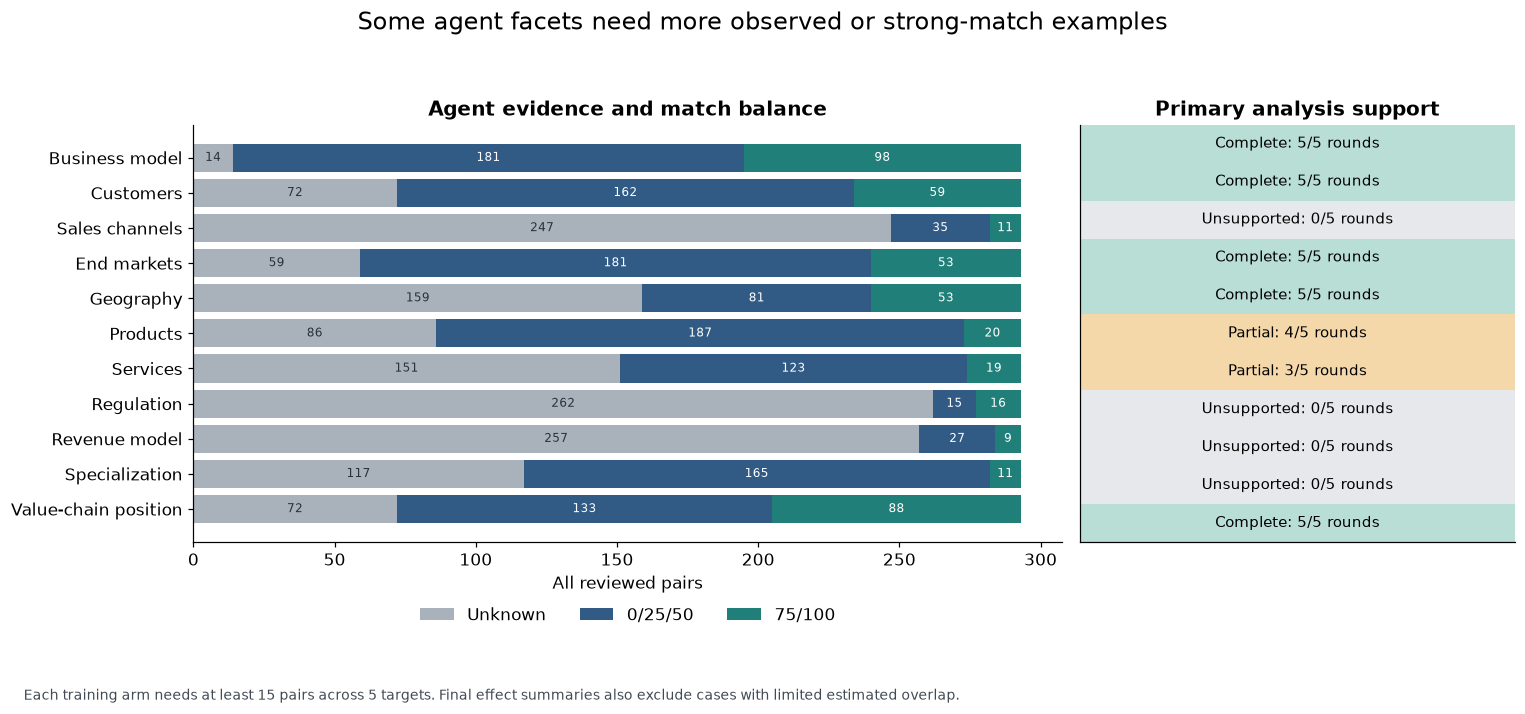

**Coverage finding**  
B3: 11 complete primary analyses. Agent: 5 complete, 2 partial, 4 unsupported. Products have only 20 strong-match pairs; services have 19. Revenue-model evidence is missing for 257 of 293 pairs.

In [12]:
part=primary[primary.source.eq("agent")].sort_values("facet").reset_index(drop=True)
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(14,6.5),gridspec_kw={"width_ratios":[2,1]})
y=np.arange(len(part));left=np.zeros(len(part))
for category,color,selector in [("Unknown",GRAY,lambda v:v.isna()),("0/25/50",BLUE,lambda v:v.le(50)),("75/100",TEAL,lambda v:v.ge(75))]:
    vals=np.array([int(selector(features['agent__'+f]).sum()) for f in part.facet])
    ax1.barh(y,vals,left=left,color=color,label=category)
    for i,(n,l) in enumerate(zip(vals,left)):
        if n>=9:ax1.text(l+n/2,i,str(n),ha="center",va="center",fontsize=8,color="white" if category!="Unknown" else "#26323d")
    left+=vals
ax1.set_yticks(y,[NAMES[f] for f in part.facet]);ax1.invert_yaxis();ax1.set(xlabel="All reviewed pairs",title="Agent evidence and match balance")
ax1.legend(loc="upper center",bbox_to_anchor=(.5,-.12),ncol=3,frameon=False)
status=np.array([[0 if r.folds_ok==0 else 1 if r.folds_ok<5 else 2] for _,r in part.iterrows()])
ax2.imshow(status,cmap=ListedColormap(["#e6e8eb","#f4d8aa","#b9ded5"]),vmin=0,vmax=2,aspect="auto")
for i,r in part.iterrows():
    label="Unsupported" if r.folds_ok==0 else "Partial" if r.folds_ok<5 else "Complete"
    ax2.text(0,i,f"{label}: {int(r.folds_ok)}/5 rounds",ha="center",va="center",fontsize=10)
ax2.set_yticks([]);ax2.set_xticks([]);ax2.set_title("Primary analysis support")
fig.suptitle("Some agent facets need more observed or strong-match examples",fontsize=16)
save(fig,"06_agent_support","Each training arm needs at least 15 pairs across 5 targets. Final effect summaries also exclude cases with limited estimated overlap.")
complete=int(part.status.eq("complete").sum()); partial=int(part.folds_ok.between(1,4).sum());unsupported=int(part.folds_ok.eq(0).sum())
block("Coverage finding",f"B3: 11 complete primary analyses. Agent: {complete} complete, {partial} partial, {unsupported} unsupported. Products have only {int(features.agent__primary_products.ge(75).sum())} strong-match pairs; services have {int(features.agent__primary_services.ge(75).sum())}. Revenue-model evidence is missing for {int(features.agent__revenue_model.isna().sum())} of {len(features)} pairs.")

<a id="comparison"></a>
## How the findings differ — and what to investigate next

The following comparison keeps outcome units separate. Changing the outcome also changes the response estimator (logistic vs bounded ridge), so differences are not solely the effect of retaining labels. There is no single combined ranking across the two methods.

- **Core B3 priorities persist:** customers, end markets, services and products are positive under both outcome definitions and both tested match contrasts. Prioritize new reviewer labels and frozen pipeline ablations for these hypotheses.
- **Some findings depend on the question:** core offering and value-chain position change when assessing expected rating rather than any acceptable peer label. Check the specific pair cases instead of translating one method's score into the other's units.
- **Large partial agent estimates need restraint:** retaining 0/1/2 changes the product/service story, but does not create additional strong-match examples or independent targets. Treat these as data-collection hypotheses rather than new weights.
- **Independent review is still needed:** only 24 pairs are direct peers and all labels come from one reviewer. A second reviewer and additional targets are important for testing whether the findings generalize.

Neither analysis shows that changing facet weights improves B3 or B3 + agent review, and neither establishes causal CATE.

In [13]:
comparisons=[]
for source in ['b3','agent']:
    for facet in sorted(DATA['rating']['facet_summary'].query('source==@source').facet.unique()):
        a,b=result_row('rating',source,facet),result_row('peer',source,facet)
        comparisons.append({'Source':source,'Facet':NAMES[facet],
            'A: rating points':a.mean_uplift,'B: percentage points':100*b.mean_uplift,
            'Evaluation rounds':int(a.folds_ok),'Retained pairs':a.overlap_pairs})
display(pd.DataFrame(comparisons).round(3))
for source,facet in [('b3','offering_description'),('b3','value_chain_position'),('agent','primary_products'),('agent','primary_services'),('agent','value_chain_position')]:
    a,b=result_row('rating',source,facet),result_row('peer',source,facet)
    block(f'{source.upper()} {NAMES[facet]}',f"A: {effect_text(a.mean_uplift,'rating')}; B: {effect_text(b.mean_uplift,'peer')}. {int(a.folds_ok)}/5 rounds; {int(a.overlap_pairs)} retained pairs. Units and outcome models differ.")


,Source,Facet,A: rating points,B: percentage points,Evaluation rounds,Retained pairs
0,b3,Customers,0.247,20.227,5,280.0
1,b3,Sales channels,0.029,1.887,5,259.0
2,b3,End markets,0.242,21.340,5,274.0
3,b3,Geography,-0.010,0.220,5,292.0
4,b3,Core offering,0.002,5.145,5,240.0
5,b3,Products,0.165,14.707,5,163.0
6,b3,Services,0.230,23.672,5,174.0
7,b3,Regulation,0.102,9.770,5,266.0
8,b3,Revenue model,0.101,9.159,5,248.0
9,b3,Specialization,0.096,4.595,5,268.0


**B3 Core offering**  
A: +0.002 rating points; B: +5.1 percentage points. 5/5 rounds; 240 retained pairs. Units and outcome models differ.

**B3 Value-chain position**  
A: -0.001 rating points; B: -4.2 percentage points. 5/5 rounds; 261 retained pairs. Units and outcome models differ.

**AGENT Products**  
A: +0.446 rating points; B: +1.6 percentage points. 4/5 rounds; 41 retained pairs. Units and outcome models differ.

**AGENT Services**  
A: +0.349 rating points; B: -0.2 percentage points. 3/5 rounds; 25 retained pairs. Units and outcome models differ.

**AGENT Value-chain position**  
A: -0.005 rating points; B: +8.2 percentage points. 5/5 rounds; 130 retained pairs. Units and outcome models differ.

## Technical appendix and reproducibility

Features and source labels are identical across the two pinned runs; no LLM calls, financial reads or matching changes occurred. The original binary outputs and technical notebook are preserved. Each presentation execution writes a new folder under the rating run, recording both runs' input hashes.

Reproduce Method A with `uv run python v1/scripts/facet_uplift.py --outcome rating`; Method B uses `--outcome peer` (the default). Update pinned paths only when intentionally reviewing a new run.

Limitations shared by both methods: observational match groups, selected candidate sample, correlated facets, potentially shared comp companies across target folds, one reviewer, fixed-prediction intervals, and no untouched independent label benchmark. Imputed effects are estimates, not known alternative outcomes. Do not sum effects, rank comp quality by uplift, or interpret missing agent scores as weak matches.

In [14]:
for mode in ['rating','peer']:
    block('Detailed fold exclusions: '+mode,'Unsupported folds stay visible; no forced estimates.')
    f=DATA[mode]['fold_diagnostics']
    display(f.loc[~f.status.eq('ok'),['source','facet','rule','fold','controls','treated','targets_arm_0','targets_arm_1','status']])
presentation_manifest={'notebook':'facet_uplift_stakeholder.ipynb','runs':{},'figures':sorted(p.name for p in PRESENTATION.glob('*.png'))}
for mode,folder in [('rating',RATING_RUN),('peer',BINARY_RUN)]:
    presentation_manifest['runs'][mode]={'run':folder.name,'input_sha256':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in [folder/'manifest.json',folder/'pair_features.csv',folder/'facet_summary.csv',folder/'oof_effects.csv',folder/'fold_diagnostics.csv']}}
assert len(presentation_manifest['figures'])==8
(PRESENTATION/'manifest.json').write_text(json.dumps(presentation_manifest,indent=2)+'\n')
print('Eight figures exported; original experiment inputs were read only.')

**Detailed fold exclusions: rating**  
Unsupported folds stay visible; no forced estimates.

,source,facet,rule,fold,controls,treated,targets_arm_0,targets_arm_1,status
111,agent,primary_products,primary,1,165,14,32,8,insufficient_support
116,agent,primary_products,extreme,1,122,14,32,8,insufficient_support
121,agent,primary_services,primary,1,86,14,23,8,insufficient_support
123,agent,primary_services,primary,3,105,14,24,6,insufficient_support
126,agent,primary_services,extreme,1,40,14,20,8,insufficient_support
128,agent,primary_services,extreme,3,58,14,21,6,insufficient_support
160,agent,revenue_model,primary,0,23,5,12,4,insufficient_support
161,agent,revenue_model,primary,1,24,7,14,5,insufficient_support
162,agent,revenue_model,primary,2,22,9,12,7,insufficient_support
163,agent,revenue_model,primary,3,22,7,13,6,insufficient_support


**Detailed fold exclusions: peer**  
Unsupported folds stay visible; no forced estimates.

,source,facet,rule,fold,controls,treated,targets_arm_0,targets_arm_1,status
111,agent,primary_products,primary,1,165,14,32,8,insufficient_support
116,agent,primary_products,extreme,1,122,14,32,8,insufficient_support
121,agent,primary_services,primary,1,86,14,23,8,insufficient_support
123,agent,primary_services,primary,3,105,14,24,6,insufficient_support
126,agent,primary_services,extreme,1,40,14,20,8,insufficient_support
128,agent,primary_services,extreme,3,58,14,21,6,insufficient_support
160,agent,revenue_model,primary,0,23,5,12,4,insufficient_support
161,agent,revenue_model,primary,1,24,7,14,5,insufficient_support
162,agent,revenue_model,primary,2,22,9,12,7,insufficient_support
163,agent,revenue_model,primary,3,22,7,13,6,insufficient_support


Eight figures exported; original experiment inputs were read only.
